# Optimo Investment — USD/CLP Quantitative Strategy

**Renato Ortega — rortegal@fen.uchile.cl · Benjamín Mundaca — bmundacam@fen.uchile.cl**

Este notebook presenta el backtest exploratorio 2019–2024: Extra Trees, 97 características D2 y política argmax, con 1.524 posiciones −1/+1. Entrenamiento expansivo desde 2010, reajuste anual y selección/calibración temporales con purga `known < decision`.

El modelo operativo se preparó posteriormente con 4.105 pares conocidos hasta el **06/11/2026**, con parámetros previamente fijados. **Las métricas del notebook no evalúan ese ajuste final.** La inferencia diaria utiliza parámetros congelados.

La estrategia simula ejecución al cierre con PX_LAST y predictores conocidos hasta la jornada anterior. Carry CLICP/FEDL01 y costos 0/1/5 pb son estimaciones documentadas, no puntaje oficial. Sólo se muestran agregados compatibles con la distribución de datos; no se cargan observaciones privadas ni modelos.

2019–2024 fue reutilizado en investigación: no constituye una validación confirmatoria independiente.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, HTML
PACKAGE = Path.cwd()
assert (PACKAGE / 'reports/carry_totales.csv').exists(), 'Ejecutar desde la raíz del paquete'
sys.path.insert(0, str(PACKAGE.resolve()))
from itau_entrega import reporting_carry as report
from itau_entrega.carry import ledger, factors
print('Sólo agregados compartibles; sin cargar datos privados ni modelos')

Sólo agregados compartibles; sin cargar datos privados ni modelos


## Modelo, características y calidad predictiva
D2 resume historia USD/CLP, dólar global, commodities, monedas emergentes, tasas y riesgo/renta variable. Sus 97 nombres están en `config/features.json`; no se añadieron CLICP/FEDL01 a los predictores. Las ausencias siguen el tratamiento original, ajustado dentro del entrenamiento. La información de X precede a la decisión t; simulación a PX_LAST(t) hasta el siguiente cierre auténtico.

DM compara el mismo objetivo triclase con Laplace dinámica: p=0,313, sin ventaja robusta. No se comparan log loss de etiquetas distintas.

In [2]:
display(HTML(report.table(report.validation_metrics(), ['id','n','accuracy','balanced_accuracy','logloss','brier','ece'])))
display(HTML(report.table(report.rows('diebold_mariano.csv'), ['id','reference','n','delta','statistic','p','method'])))

id,n,accuracy,balanced_accuracy,logloss,brier,ece
E2010__extra_dir,1524,0.533465,0.357094,0.72698,0.505391,0.0215258
baseline__laplace_dynamic,1524,0.502625,0.330743,0.728573,0.506568,0.00428292


id,reference,n,delta,statistic,p,method
ExtraTrees,Laplace_dynamic,1524,-0.00159234,-1.00928,0.313001,DM HAC Bartlett; HLN h1; t n-1; exploratory


## Contabilidad: retorno total CLP y exceso sobre caja
C es la variación del índice CLICP, **no una tasa en niveles**. U acumula FEDL01 (% anual /100, ACT/360) por días calendario, manteniendo el último dato económico en fines de semana/ausencias. Para extremos CLICP ausentes se estima el nivel entre observaciones auténticas acotadas hasta siete días; no se extrapola ni se cambia la imputación de D2. Ambos devengos son contabilidad ex post, nunca señales futuras.

`R = C + q * [r + (1+r)*U − C] − costos`. Así q=0 cobra caja C y q=+1 no recibe además otra caja CLP. Se asume inversión/financiación simétrica, sin spreads ni fricciones adicionales. Costos hipotéticos 0/1/5 pb por unidad de rotación, incluyendo entrada/salida. `W = producto(1+R)` es patrimonio compuesto; las sumas spot/carry/caja/costos son descomposición sobre nocional fijo y **no se suman al retorno compuesto**.

Volatilidad de R por sqrt(252); Sharpe del exceso por intervalo frente a caja C, no Sharpe oficial. Hit económico: exceso positivo entre jornadas expuestas; hit total: R positivo. Órdenes: cambios de q más liquidación final; reversión ±1 rota dos unidades. La posición cero gana caja, no resultado económico cero. Comprar siempre y exposición +1 son la misma referencia.

In [3]:
totals = report.rows('carry_totales.csv')
display(HTML(report.table(totals, ['policy','cost_bps','n','net_compounded','relative_to_cash','vol_annual','sharpe_excess_cash','max_drawdown','hit_excess_exposed','hit_total','orders','turnover','mean_absolute_exposure'])))
display(HTML(report.table([r for r in totals if r['cost_bps']=='1'], ['policy','spot_sum','base_cash_sum','clp_financing_sum','usd_income_sum','carry_sum','cost_sum','total_sum'])))

policy,cost_bps,n,net_compounded,relative_to_cash,vol_annual,sharpe_excess_cash,max_drawdown,hit_excess_exposed,hit_total,orders,turnover,mean_absolute_exposure
ExtraTrees_E2010,0,1524,0.818555,0.347424,0.144617,0.413983,-0.253942,0.533465,0.544619,461,920,1
ExtraTrees_E2010,1,1524,0.658733,0.229007,0.144637,0.308601,-0.267688,0.528871,0.540026,461,920,1
ExtraTrees_E2010,5,1524,0.14788,-0.149499,0.144867,-0.112512,-0.32021,0.515748,0.527559,461,920,1
buy,0,1524,0.661351,0.230947,0.144572,0.310222,-0.243102,N/D,N/D,2,2,1
buy,1,1524,0.661019,0.230701,0.144572,0.309994,-0.243102,N/D,N/D,2,2,1
buy,5,1524,0.659692,0.229718,0.144571,0.309078,-0.243102,N/D,N/D,2,2,1
cash_zero,0,1524,0.349652,0,0.00342102,N/D,0,N/D,N/D,0,0,0
cash_zero,1,1524,0.349652,0,0.00342102,N/D,0,N/D,N/D,0,0,0
cash_zero,5,1524,0.349652,0,0.00342102,N/D,0,N/D,N/D,0,0,0


policy,spot_sum,base_cash_sum,clp_financing_sum,usd_income_sum,carry_sum,cost_sum,total_sum
ExtraTrees_E2010,0.426852,0.299912,-0.14879,0.0835027,-0.0652875,0.092,0.569476
buy,0.423915,0.299912,-0.299912,0.14698,-0.152932,0.0002,0.570694
cash_zero,0,0.299912,0,0,0,0,0.299912


## Incertidumbre económica
Bootstrap circular **pareado** de diferencias en exceso por intervalo, bloques de 10 observaciones, 1.999 réplicas, semilla 20261112. IC95% para diferencia media por intervalo, no para riqueza compuesta. Holm: seis contrastes estrategia frente a comprar/caja en costos 0/1/5. Todos los intervalos incluyen cero. No se seleccionan escenarios favorables ni se cambian posiciones.

A 1 pb la estrategia queda descriptivamente próxima a comprar, con más rotación; a 5 pb pierde gran parte del resultado y queda bajo caja. No se acredita superioridad económica.

CLICP: 30 extremos únicos estimados de 1.525; 60 apariciones y 54 intervalos afectados. Sensibilidad sobre las mismas 1.524 jornadas: log-lineal principal, índice anterior e índice posterior, sólo dentro de brechas acotadas. A 1 pb, retorno compuesto 65,8733% principal frente a 67,1524% anterior y 65,3513% posterior. No se selecciona el escenario más favorable; ver metodología. No se publican fechas/valores ni métricas del subgrupo pequeño.

In [4]:
display(HTML(report.table(report.rows('carry_bootstrap.csv'), ['reference','cost_bps','n','delta','lo','hi','p','p_holm','block','reps'])))
coverage = json.loads((PACKAGE / 'reports/carry_cobertura.json').read_text(encoding='utf-8'))
print('Extremos únicos:', coverage['clp_unique_endpoints'], 'estimados:', coverage['clp_unique_estimated_endpoints'], 'apariciones:', coverage['clp_estimated_endpoint_appearances'], 'intervalos afectados:', coverage['clp_intervals_affected'])
display(HTML(report.table([r for r in report.rows('carry_sensibilidad.csv') if r['policy']=='ExtraTrees_E2010' and r['cost_bps']=='1'], ['method','n','net_compounded','delta_net_compounded','sharpe_excess_cash','max_drawdown'])))

reference,cost_bps,n,delta,lo,hi,p,p_holm,block,reps
buy,0,1524,5.94369e-05,-0.000491739,0.000577817,0.8255,1,10,1999
buy,1,1524,-7.99362e-07,-0.000547021,0.000515839,0.9985,1,10,1999
buy,5,1524,-0.000241744,-0.000780232,0.00027799,0.3675,1,10,1999
cash_zero,0,1524,0.000237247,-0.000166908,0.000628732,0.2395,1,10,1999
cash_zero,1,1524,0.000176879,-0.000229019,0.000567475,0.384,1,10,1999
cash_zero,5,1524,-6.45905e-05,-0.000472262,0.000324565,0.768,1,10,1999


Extremos únicos: 1525 estimados: 30 apariciones: 60 intervalos afectados: 54


method,n,net_compounded,delta_net_compounded,sharpe_excess_cash,max_drawdown
log_linear,1524,0.658733,0,0.308601,-0.267688
previous_native,1524,0.671524,0.012791,0.317417,-0.267758
next_native,1524,0.653513,-0.00521939,0.30492,-0.26776


## Resultados visuales agregados

Los puntos de patrimonio muestran el capital inicial y el cierre de dos bloques trienales. No describen ni permiten reconstruir la trayectoria diaria. El drawdown mostrado es el máximo global, no una curva temporal. Las exposiciones y la sensibilidad a costos son resúmenes del mismo backtest; no se han elegido otros períodos ni modificado posiciones.

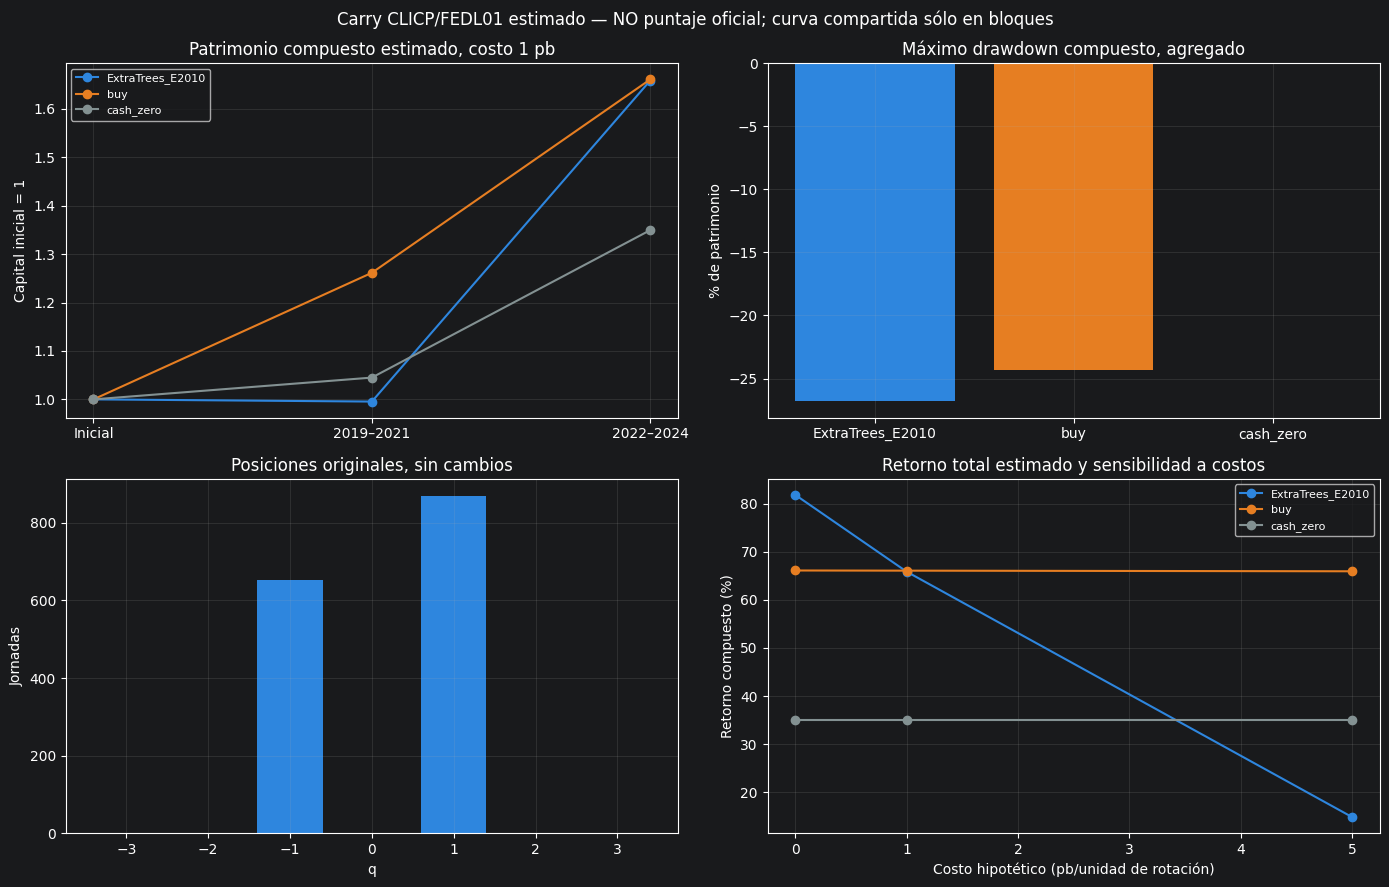

In [5]:
import matplotlib.pyplot as plt
fig = report.plots()
plt.show()

## Reproducción e investigación

El backtest histórico se reproduce con `python -m itau_entrega reproduce --excel data/raw/base_usdclp_actualizada.xlsx --output outputs/reproduccion`. Mantiene el protocolo histórico; no debe confundirse con la preparación inicial del modelo operativo mediante `fit-deployment`.

La matriz presenta alternativas efectivamente evaluadas. Extra Trees es una elección operativa de un pipeline auditado, sin evidencia de dominancia estadística general. Se conservan resultados negativos y limitaciones por reutilización de 2019–2024. La estrategia define ejecución simulada al cierre; la activación real requiere compatibilidad del monitor, feed certificado y convenciones económicas del sistema de evaluación.

Los casos siguientes son **ejemplos sintéticos manuales**, separados de los resultados históricos.

In [6]:
synthetic=[]
for name,q in [('caja',0),('largo',1),('corto',-1)]:
    l=ledger([0.02],[q],[0.001],[0.0005],0)
    synthetic.append(dict(caso=name,spot=float(l['spot'][0]),carry=float(l['carry'][0]),caja=0.001,total=float(l['total'][0])))
display(HTML(report.table(synthetic,['caso','spot','carry','caja','total'])))
print('Fin de semana sintético: USD 3,6% anual ACT/360 por tres días =', (1+0.036/360)**3-1)
display(HTML(report.table(report.rows('matriz_experimentos.csv'), ['phase','id','objective','n','logloss','accuracy','mse','rmse','r2_zero'])))

{'predictions': 1524, 'positions_identical': True, 'features': 97, 'feature_rows': 3638, 'features_exact_with_nan': True, 'max_scoring_delta': 2.220446049250313e-16, 'tolerance': 1e-12, 'model_code_unchanged': True, 'no_retraining': True, 'neutral_decisions': 0, 'reserved_values_used': False, 'official_economic_score': False, 'tests': 53, 'notebook_executed': True, 'plots_visually_reviewed': True, 'original_protected_files_matching': 2187, 'source_sha256': 'a198a2357332685b784fddd852dea242f59e90046dedd9709a3429ae9f6134ee', 'clean_remote_clone_performed': False, 'official_net': False, 'carry_included_estimated': True, 'carry_index_interpolation_disclosed': True}


caso,spot,carry,caja,total
caja,0,-0,0.001,0.001
largo,0.02,-0.00049,0.001,0.02051
corto,-0.02,0.00049,0.001,-0.01851


Fin de semana sintético: USD 3,6% anual ACT/360 por tres días = 0.00030003000099987354


phase,id,objective,n,logloss,accuracy,mse,rmse,r2_zero
Fase6,cat__D2,direction_original,1524,0.727075,0.526903,N/D,N/D,N/D
Fase6,cat__V2,direction_original,1524,0.728136,0.501969,N/D,N/D,N/D
Fase6,lgbm__D2,direction_original,1524,0.736138,0.485564,N/D,N/D,N/D
Fase6,lgbm__V2,direction_original,1524,0.732747,0.503937,N/D,N/D,N/D
Fase6,xgb__D2,direction_original,1524,0.738248,0.496719,N/D,N/D,N/D
Fase6,xgb__V2,direction_original,1524,0.733831,0.513123,N/D,N/D,N/D
Fase6,histgb__D2,direction_original,1524,0.736744,0.501969,N/D,N/D,N/D
Fase6,histgb__V2,direction_original,1524,0.735573,0.509843,N/D,N/D,N/D
Fase6,svc__D2,direction_original,1524,0.871551,0.520341,N/D,N/D,N/D
Fase6,svc__V2,direction_original,1524,0.873852,0.520341,N/D,N/D,N/D
